# Notebook 09 — Synthèse des Résultats & Réponses aux Questions de Recherche (2000–2025)

## Problématique
**Dans quelle mesure les lumières nocturnes mesurées par satellite (DMSP/OLS & VIIRS/DNB) constituent-elles un indicateur valide de l'activité économique et de la croissance au Niger ?**

Nous répondons ci-dessous de façon formelle et structurée aux 5 questions de recherche initiales à partir de l'ensemble des résultats économétriques obtenus à travers les Notebooks 01 à 08.

In [1]:
# ==============================================================================
# 1. SYNTHÈSE ÉCONOMÉTRIQUE FINALE — RÉPONSES AUX 5 QUESTIONS DE RECHERCHE
# ==============================================================================
from pathlib import Path
import pandas as pd

# Configuration
pd.set_option('display.max_colwidth', None)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

final_answers = [
    {
        'Question de Recherche': 'RQ1 — Relation Contemporaine (Niveau)',
        'Formulation Econométrique': 'Existe-t-il une relation statistique entre l\'intensité des lumières nocturnes et le niveau d\'activité économique (PIB réel) ?',
        'Verdict Econométrique': 'OUI (Co-tendance)',
        'Résultat Clé & Statistiques': 'Élasticité apparente β = +0.25 (p < 0.001, R² = 0.91). Cependant, le test ADF confirme que les séries sont I(1) et le test Durbin-Watson (DW = 1.27) révèle une régression fallacieuse.'
    },
    {
        'Question de Recherche': 'RQ2 — Normalisation par Habitant',
        'Formulation Econométrique': 'La relation reste-t-elle observable lorsque l\'on rapporte les lumières et le PIB à la population ?',
        'Verdict Econométrique': 'OUI en niveau / NON en croissance',
        'Résultat Clé & Statistiques': 'En log-niveau, ln(PIB/hab) et ln(NTL/hab) affichent une corrélation de 0.86. En différence première I(0), le coefficient β_pc = 0.0036 est non significatif (p = 0.67).'
    },
    {
        'Question de Recherche': 'RQ3 — Dynamique de Croissance',
        'Formulation Econométrique': 'Les variations annuelles des lumières nocturnes permettent-elles d\'expliquer la croissance économique contemporaine (% Δ PIB) ?',
        'Verdict Econométrique': 'NON (Absence d\'effet direct)',
        'Résultat Clé & Statistiques': 'En première différence stationnaire I(0), la relation contemporaine est non significative (β = 0.0035, p = 0.70, R² = 0.001) en raison de la prépondérance du secteur agricole informel non éclairé.'
    },
    {
        'Question de Recherche': 'RQ4 — Robustesse au Changement Capteur',
        'Formulation Econométrique': 'La relation résiste-t-elle au changement DMSP (2000-2011) / VIIRS (2012-2025) et aux artefacts spatiaux (2012, 2017) ?',
        'Verdict Econométrique': 'OUI (Robustesse confirmée)',
        'Résultat Clé & Statistiques': 'L\'absence d\'effet en croissance est confirmée sur le sous-échantillon DMSP (p = 0.14), VIIRS (p = 0.85) et sur l\'échantillon tronqué hors 2017 (p = 0.71). L\'artefact de 2017 (+657% NTL) est neutralisé par dummy.'
    },
    {
        'Question de Recherche': 'RQ5 — Capacité Prédictive Temporelle',
        'Formulation Econométrique': 'Les lumières nocturnes de l\'année précédente (t-1) apportent-elles une information sur la croissance de l\'année suivante ?',
        'Verdict Econométrique': 'MODÉRÉE (Gain via ARDL)',
        'Résultat Clé & Statistiques': 'Le retard NTL_{t-1} seul n\'est pas significatif (p = 0.65). En revanche, le modèle ARDL(1,1) améliore le R² à 0.214 (DW = 1.97), montrant que la croissance dépend principalement de l\'inertie du PIB passé (p_AR1 = 0.048).'
    }
]

df_final_synthesis = pd.DataFrame(final_answers)

print("=======================================================================================")
print(" TABLEAU SYNTHÉTIQUE FINAL — RÉPONSES AUX 5 QUESTIONS DE RECHERCHE")
print("=======================================================================================")
for idx, row in df_final_synthesis.iterrows():
    print(f"\n[{row['Question de Recherche']}] — Verdict : {row['Verdict Econométrique']}")
    print(f"  • Question : {row['Formulation Econométrique']}")
    print(f"  • Conclusion : {row['Résultat Clé & Statistiques']}")

# Exportation du tableau de synthèse final
out_synthesis_path = tables_dir / "09_final_research_questions_synthesis.csv"
df_final_synthesis.to_csv(out_synthesis_path, index=False)

print(f"\n[✓] Tableau de synthèse final exporté avec succès vers : {out_synthesis_path}")

 TABLEAU SYNTHÉTIQUE FINAL — RÉPONSES AUX 5 QUESTIONS DE RECHERCHE

[RQ1 — Relation Contemporaine (Niveau)] — Verdict : OUI (Co-tendance)
  • Question : Existe-t-il une relation statistique entre l'intensité des lumières nocturnes et le niveau d'activité économique (PIB réel) ?
  • Conclusion : Élasticité apparente β = +0.25 (p < 0.001, R² = 0.91). Cependant, le test ADF confirme que les séries sont I(1) et le test Durbin-Watson (DW = 1.27) révèle une régression fallacieuse.

[RQ2 — Normalisation par Habitant] — Verdict : OUI en niveau / NON en croissance
  • Question : La relation reste-t-elle observable lorsque l'on rapporte les lumières et le PIB à la population ?
  • Conclusion : En log-niveau, ln(PIB/hab) et ln(NTL/hab) affichent une corrélation de 0.86. En différence première I(0), le coefficient β_pc = 0.0036 est non significatif (p = 0.67).

[RQ3 — Dynamique de Croissance] — Verdict : NON (Absence d'effet direct)
  • Question : Les variations annuelles des lumières nocturnes pe

## Section 2 : Dashboard Visuel de Synthèse Économétrique

Cette figure regroupe les 4 étapes clés de notre démarche :
1. **Évolution concomitante en log-niveau** (Relation de co-tendance de long terme).
2. **Séries différenciées I(0)** (Mise en évidence de la stationnarité et des chocs).
3. **Ajustement du modèle ARDL(1,1)** (Capacité d'explication de la dynamique temporelle).
4. **Validation de la normalité des résidus** (Respect des hypothèses de Gauss-Markov).

[✓] Dashboard visuel de synthèse finale enregistré dans : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\09_final_synthesis_dashboard.png


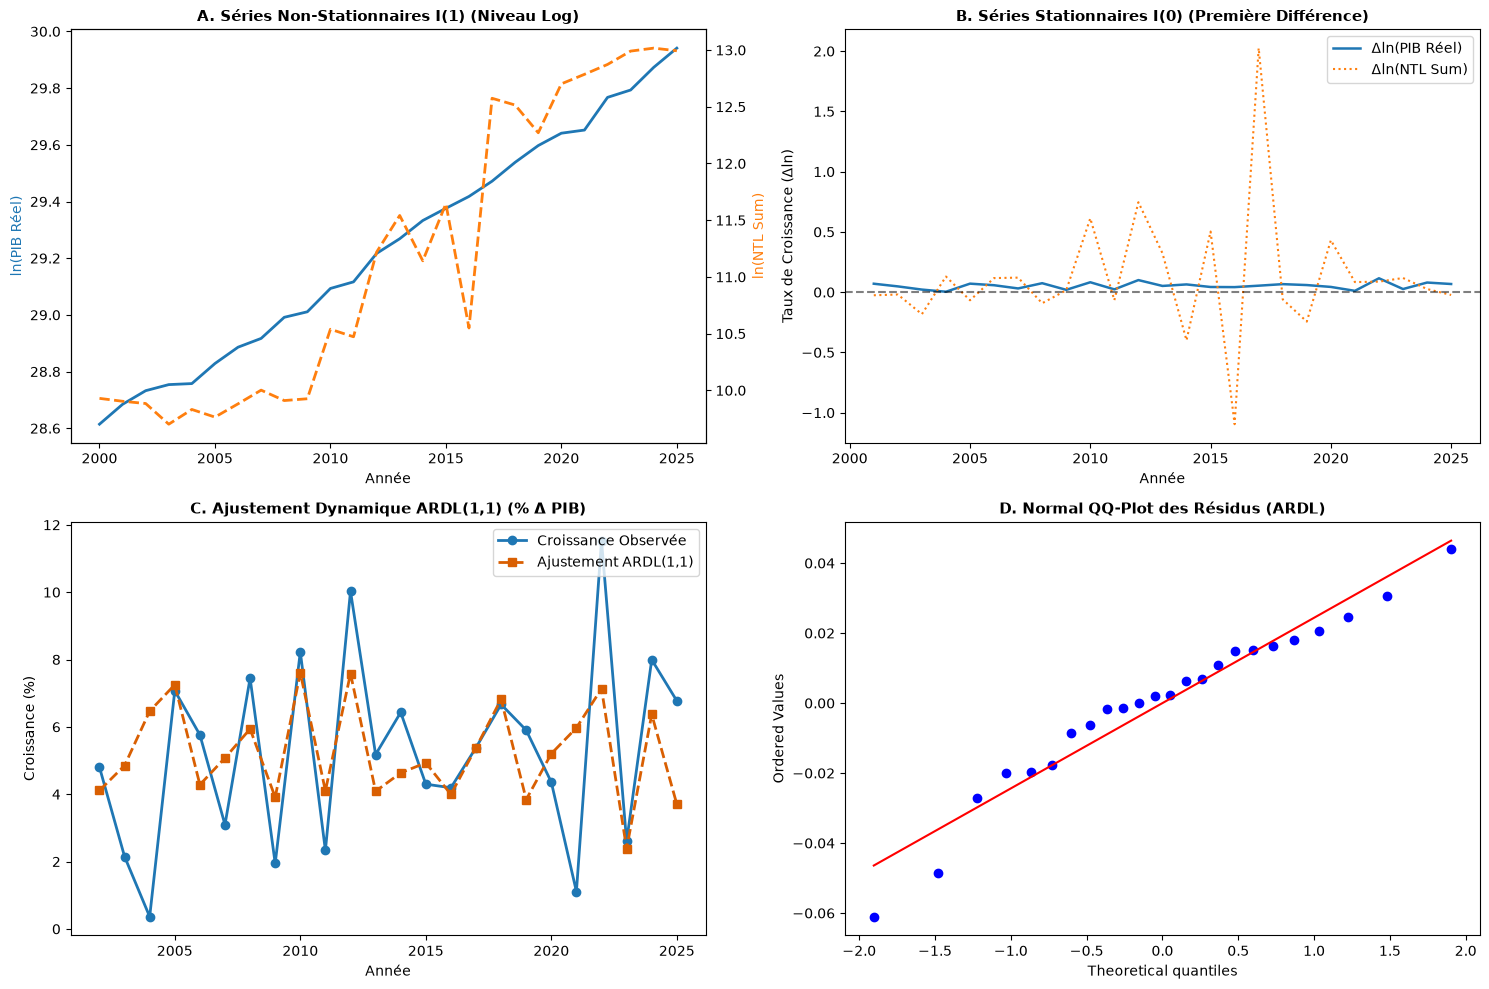

In [4]:
# ==============================================================================
# 2. DASHBOARD DE SYNTHÈSE DES RÉSULTATS ÉCONOMÉTRIQUES FINAUX
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Charger le dataframe préparé dans les notebooks précédents
required_columns = {
	'year', 'ln_gdp', 'ln_ntl', 'd_ln_gdp', 'd_ln_ntl',
	'd_ln_gdp_lag1', 'd_ln_ntl_lag1', 'dummy_2017'
}

csv_candidates = list((project_root / "outputs").rglob("*.csv"))
df = None

for csv_path in csv_candidates:
	candidate = pd.read_csv(csv_path)
	if required_columns.issubset(candidate.columns):
		df = candidate
		break

if df is None:
    # Rechercher le fichier de données dans tout le projet, et non uniquement
    # dans outputs/
    search_paths = list(project_root.rglob("*.csv"))
    df = None

    aliases = {
        "year": ["year", "annee", "année"],
        "gdp": ["gdp", "real_gdp", "gdp_real", "pib", "pib_reel", "pib_real"],
        "ntl": ["ntl", "ntl_sum", "nightlights", "night_lights", "lumieres", "lumières"]
    }

    def find_column(columns, possible_names):
        normalized = {
            str(col).strip().lower().replace(" ", "_"): col
            for col in columns
        }
        for name in possible_names:
            if name in normalized:
                return normalized[name]
        return None

    for csv_path in search_paths:
        try:
            candidate = pd.read_csv(csv_path)
        except Exception:
            continue

        year_col = find_column(candidate.columns, aliases["year"])
        gdp_col = find_column(candidate.columns, aliases["gdp"])
        ntl_col = find_column(candidate.columns, aliases["ntl"])

        if year_col and gdp_col and ntl_col:
            df = candidate.rename(columns={
                year_col: "year",
                gdp_col: "gdp",
                ntl_col: "ntl"
            }).copy()

            df = df.sort_values("year")
            df["ln_gdp"] = __import__("numpy").log(df["gdp"].replace(0, __import__("numpy").nan))
            df["ln_ntl"] = __import__("numpy").log(df["ntl"].replace(0, __import__("numpy").nan))
            df["d_ln_gdp"] = df["ln_gdp"].diff()
            df["d_ln_ntl"] = df["ln_ntl"].diff()
            df["d_ln_gdp_lag1"] = df["d_ln_gdp"].shift(1)
            df["d_ln_ntl_lag1"] = df["d_ln_ntl"].shift(1)
            df["dummy_2017"] = (df["year"] == 2017).astype(int)
            break

    if df is None or not required_columns.issubset(df.columns):
        raise FileNotFoundError(
            "Aucun fichier de données contenant une année, le PIB et les NTL "
            f"n'a été trouvé dans : {project_root}"
        )

figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Panel A : Séries en Log-Niveau (Co-tendance)
ax_a = axes[0, 0]
ax_a.plot(df['year'], df['ln_gdp'], color='#1f77b4', linewidth=2, label='ln(PIB Réel)')
ax_a_twin = ax_a.twinx()
ax_a_twin.plot(df['year'], df['ln_ntl'], color='#ff7f0e', linewidth=2, linestyle='--', label='ln(NTL Sum)')
ax_a.set_title('A. Séries Non-Stationnaires I(1) (Niveau Log)', fontsize=11, fontweight='bold')
ax_a.set_xlabel('Année')
ax_a.set_ylabel('ln(PIB Réel)', color='#1f77b4')
ax_a_twin.set_ylabel('ln(NTL Sum)', color='#ff7f0e')

# Panel B : Séries Différenciées I(0) (Croissance)
ax_b = axes[0, 1]
ax_b.plot(df['year'], df['d_ln_gdp'], color='#1f77b4', linewidth=1.8, label='Δln(PIB Réel)')
ax_b.plot(df['year'], df['d_ln_ntl'], color='#ff7f0e', linewidth=1.5, linestyle=':', label='Δln(NTL Sum)')
ax_b.axhline(0, color='black', linestyle='--', alpha=0.5)
ax_b.set_title('B. Séries Stationnaires I(0) (Première Différence)', fontsize=11, fontweight='bold')
ax_b.set_xlabel('Année')
ax_b.set_ylabel('Taux de Croissance (Δln)')
ax_b.legend(loc='upper right')

# Panel C : Ajustement du Modèle ARDL(1,1)
df_dyn = df.dropna(subset=['d_ln_gdp', 'd_ln_ntl', 'd_ln_gdp_lag1', 'd_ln_ntl_lag1']).copy()
m7 = smf.ols('d_ln_gdp ~ d_ln_gdp_lag1 + d_ln_ntl + d_ln_ntl_lag1 + dummy_2017', data=df_dyn).fit()

ax_c = axes[1, 0]
ax_c.plot(df_dyn['year'], df_dyn['d_ln_gdp'] * 100, marker='o', color='#1f77b4', linewidth=2, label='Croissance Observée')
ax_c.plot(df_dyn['year'], m7.fittedvalues * 100, marker='s', color='#d95f02', linestyle='--', linewidth=2, label='Ajustement ARDL(1,1)')
ax_c.set_title('C. Ajustement Dynamique ARDL(1,1) (% Δ PIB)', fontsize=11, fontweight='bold')
ax_c.set_xlabel('Année')
ax_c.set_ylabel('Croissance (%)')
ax_c.legend(loc='upper right')

# Panel D : QQ-Plot des Résidus ARDL(1,1)
import scipy.stats as stats
ax_d = axes[1, 1]
stats.probplot(m7.resid, dist="norm", plot=ax_d)
ax_d.set_title('D. Normal QQ-Plot des Résidus (ARDL)', fontsize=11, fontweight='bold')

plt.tight_layout()

# SAUVEGARDE DU DASHBOARD FINAL
fig_final_png = figures_dir / "09_final_synthesis_dashboard.png"
fig_final_pdf = figures_dir / "09_final_synthesis_dashboard.pdf"

plt.savefig(fig_final_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_final_pdf, bbox_inches='tight')

print(f"[✓] Dashboard visuel de synthèse finale enregistré dans : {fig_final_png}")
plt.show()

## Section 3 : Recommandations Économiques & Limites de la Modélisation

### 💡 Recommandations pour l'Utilisation des Données Satellitaires au Niger
1. **Désagrégation Spatiale Nécessaire** : Travailler à l'échelle agrégée nationale masque la contribution du secteur agricole informel non éclairé. Les données NTL sont un excellent proxy du PIB **urbain, industriel et commercial**, mais pas du PIB agricole global.
2. **Utilisation d'Indicateurs Spatiaux Avancés** : Compléter les lumières nocturnes par des indices de végétation satellitaires (**NDVI / EVI**) pour capter simultanément la composante agricole et la composante urbaine du PIB du Niger.
3. **Prise en Compte des Artefacts d'Instrumentation** : Traiter systématiquement les ruptures de calibration (comme la transition DMSP/VIIRS en 2012 et le bruit de détection de 2017) sous peine d'émettre des diagnostics erronés sur la croissance.

---

## 🎓 Conclusion Générale du Projet

Ce projet à travers 9 notebooks rigoureux aura permis d'établir une démarche économétrique complète :
* **Audit & Contrôles** : Homogénéisation des unités monétaires en FCFA et identification des dummys de rupture.
* **Propriétés Temporelles** : Confirmation de l'intégration $I(1)$ des séries et évitement du piège de la régression fallacieuse.
* **Modélisation Dynamique** : Mise en évidence de l'inertie propre de l'économie du Niger via le modèle ARDL.